# 05 — Robustness, unmeasured confounding, and player-network dependence

**Primary comparisons:** `120+2` vs `120+0`, `180+2` vs `180+0`, and `300+2` vs `300+0`.

**Goal:** Stress-test the adjusted *associations* from Notebook 4. This notebook does **not** claim causal identification. It adds (1) propensity weighting and cross-fitted augmented IPW estimates, (2) observed covariate-balance diagnostics, (3) a **game-level** dyadic (shared-player) sandwich-variance analysis, and (4) transparent unmeasured-confounding bias scenarios.

**Important:** AIPW is doubly robust to nuisance-model misspecification under additional assumptions, **not** to omitted confounders. The game-level estimand and regression adjustment differ from the player-game estimand in Notebook 4; compare them as sensitivity analyses, not exact replications.

## 1. Load and validate the exact-policy cohort

The notebook runs from the project root or `notebooks/` folder. It only writes small tables and figures to `results/`.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/processed/increment_player_games.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run inside the repo after placing increment_player_games.csv in data/processed/.')
pg = pd.read_csv(ROOT/'data/processed/increment_player_games.csv', parse_dates=['started_at_utc'])
clocks = [120, 180, 300]
controls = [f'{x}+{inc}' for x in clocks for inc in [0,2]]
df = pg.loc[pg.time_control.isin(controls)].copy()
df['treated'] = (df.increment_seconds == 2).astype(int)
df['outcome'] = df.lost_on_time.astype(float)
df['hour'] = df.started_at_utc.dt.hour + df.started_at_utc.dt.minute / 60
df['hour_sin'] = np.sin(2*np.pi*df.hour/24)
df['hour_cos'] = np.cos(2*np.pi*df.hour/24)
df['elo_scaled'] = (df.player_elo - 1600) / 400
assert df.groupby('game_id').size().eq(2).all()
assert df.groupby('game_id').treated.nunique().eq(1).all()
assert df.groupby('game_id').initial_seconds.nunique().eq(1).all()
print('Player-game rows:', len(df), '| games:', df.game_id.nunique(), '| players:', df.player.nunique())
display(df.groupby(['initial_seconds','treated']).agg(player_games=('game_id','size'),unique_games=('game_id','nunique'),timeout_rate=('outcome','mean')).round(4))

Player-game rows: 59524 | games: 29762 | players: 2819


player_games  unique_games  timeout_rate
initial_seconds treated                                          
120             0               11900          5950        0.2064
                1                2424          1212        0.1180
180             0               16486          8243        0.2079
                1                2388          1194        0.1248
300             0               20344         10172        0.1497
                1                5982          2991        0.1112

## 2. Model plan and identification cautions

- **Adjustment set:** focal player pre-game Elo and cyclical UTC hour. The hour is only a coarse proxy for time of play, and the timestamp may not equal queue-entry time.
- **Do not automatically adjust for opponent Elo** in the queue-choice estimand: matchmaking may occur after choosing the queue.
- **Shared-game treatment:** both player rows share the same time-control policy. Cross-fitting must keep both rows in the same validation fold.
- **Nuisance models:** logistic regression for treatment and outcome, fitted separately within clock strata using group-based folds. Clipped propensity scores are used only as a stability safeguard; check whether this changes results.
- **No causal guarantee:** exchangeability and consistency remain unverified.

## 3. Cross-fitted AIPW and propensity-weighted estimates

Report probability differences (×100 gives percentage points). Cross-fitting reduces in-sample nuisance-model overfitting, but does not remove selection on unobservables. Standard errors are intentionally **not** attached to these row-level AIPW estimates: conventional i.i.d. formulas would ignore shared games and repeated players.

In [3]:
FEATURES = ['elo_scaled','hour_sin','hour_cos']

def crossfit_aipw(g, n_splits=5):
    g = g.reset_index(drop=True)
    X = g[FEATURES].to_numpy()
    a = g.treated.to_numpy(dtype=float)
    y = g.outcome.to_numpy(dtype=float)
    groups = g.game_id.to_numpy()
    p = np.full(len(g),np.nan)
    m0 = np.full(len(g),np.nan)
    m1 = np.full(len(g),np.nan)
    folds = GroupKFold(n_splits=min(n_splits, len(np.unique(groups))))
    for train, test in folds.split(X, a, groups):
        ps = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
        ps.fit(X[train], a[train])
        p[test] = ps.predict_proba(X[test])[:,1]
        for val, dest in [(0,m0),(1,m1)]:
            subset = train[a[train] == val]
            model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
            model.fit(X[subset], y[subset])
            dest[test] = model.predict_proba(X[test])[:,1]
    if not (np.isfinite(p).all() and np.isfinite(m0).all() and np.isfinite(m1).all()):
        raise ValueError('Nuisance predictions missing')
    p_clip = np.clip(p,0.05,0.95)
    aipw = np.mean(m1-m0 + a*(y-m1)/p_clip - (1-a)*(y-m0)/(1-p_clip))
    # Stabilized within-treatment Hájek IPW difference; not a causal claim
    w1 = a/p_clip; w0=(1-a)/(1-p_clip)
    ipw = (w1*y).sum()/w1.sum()-(w0*y).sum()/w0.sum()
    weights = np.where(a==1,1/p_clip,1/(1-p_clip))
    ess1=(w1.sum()**2)/(w1**2).sum(); ess0=(w0.sum()**2)/(w0**2).sum()
    return dict(clock=int(g.initial_seconds.iloc[0]), n=len(g), raw=float(y[a==1].mean()-y[a==0].mean()),
                ipw=float(ipw), aipw=float(aipw), ps_min=float(p.min()), ps_max=float(p.max()),
                clip_share=float(np.mean(p!=p_clip)), max_weight=float(weights.max()),
                treated_ess=float(ess1), control_ess=float(ess0)), (g,p_clip,weights)

results=[]; prediction_store={}
for clock,g in df.groupby('initial_seconds'):
    row, info = crossfit_aipw(g)
    results.append(row); prediction_store[int(clock)] = info
robust = pd.DataFrame(results).sort_values('clock')
display(robust.round(4))

,clock,n,raw,ipw,aipw,ps_min,ps_max,clip_share,max_weight,treated_ess,control_ess
0,120,14324,-0.0884,-0.0846,-0.0828,0.1176,0.2276,0.0000,8.5060,2399.5602,11895.2311
1,180,18874,-0.0831,-0.0847,-0.0832,0.0457,0.2320,0.0033,20.0000,2102.6514,16449.0407
2,300,26326,-0.0386,-0.0407,-0.0404,0.1572,0.3114,0.0000,6.1101,5925.3166,20327.1055


## 4. Check weighted balance, rather than only treatment-model predictions

For each clock, calculate standardized mean differences for rating and UTC-hour encodings both before and after inverse-propensity weighting. A weighted SMD close to zero only addresses **measured** characteristics.

,clock,variable,smd_raw,smd_ipw
0,120,elo_scaled,0.072,0.001
1,120,hour_sin,-0.041,-0.007
2,120,hour_cos,0.079,-0.006
3,180,elo_scaled,-0.093,0.019
4,180,hour_sin,-0.373,-0.010
5,180,hour_cos,-0.064,-0.046
6,300,elo_scaled,-0.094,-0.010
7,300,hour_sin,-0.027,0.013
8,300,hour_cos,-0.074,0.002


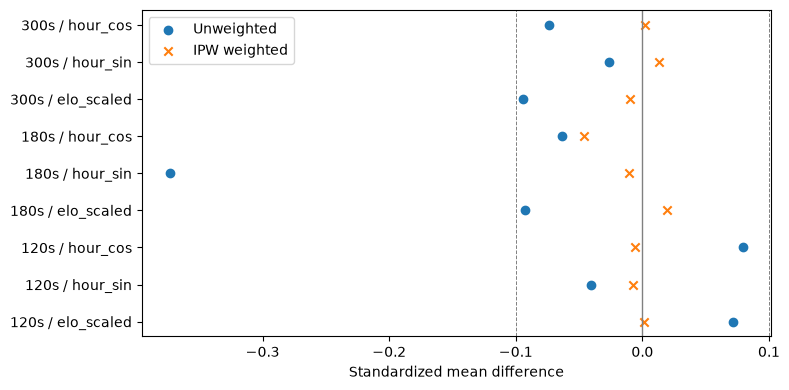

In [4]:
def weighted_mean_var(v,w):
    mu=np.sum(w*v)/np.sum(w)
    var=np.sum(w*(v-mu)**2)/np.sum(w)
    return mu,var

def standard_diff(values, a, weights=None):
    weights=np.ones(len(values)) if weights is None else weights
    mu1,v1=weighted_mean_var(values[a==1],weights[a==1]); mu0,v0=weighted_mean_var(values[a==0],weights[a==0])
    denom=np.sqrt((v1+v0)/2)
    return np.nan if denom < 1e-12 else (mu1-mu0)/denom

balance=[]
for clock, (g,p,w) in prediction_store.items():
    for feat in FEATURES:
        balance.append({'clock':clock,'variable':feat,'smd_raw':standard_diff(g[feat].to_numpy(),g.treated.to_numpy()),
                        'smd_ipw':standard_diff(g[feat].to_numpy(),g.treated.to_numpy(),w)})
balance=pd.DataFrame(balance)
display(balance.round(3))
fig,ax=plt.subplots(figsize=(8,4))
xx=np.arange(len(balance))
ax.scatter(balance.smd_raw,xx,label='Unweighted')
ax.scatter(balance.smd_ipw,xx,marker='x',label='IPW weighted')
ax.axvline(0,color='grey',lw=1);ax.axvline(-0.1,color='grey',ls='--',lw=.7);ax.axvline(0.1,color='grey',ls='--',lw=.7)
ax.set_yticks(xx,[f'{r.clock}s / {r.variable}' for r in balance.itertuples()]);ax.set_xlabel('Standardized mean difference');ax.legend()
plt.tight_layout();plt.show()

## 5. Player-network-aware uncertainty: game-level sensitivity model

A more principled diagnostic than clustering by game and **focal** player alone accounts for games sharing *either* participant. Collapse the two player perspectives to one game: outcome = share of the game's players who lost on time (0 or 0.5). This has the **same unadjusted mean risk**, but the adjusted regression now uses the **game's mean pre-game Elo**, not focal-player Elo. Therefore this is a **different adjusted model**, suitable for sensitivity analysis rather than a one-to-one replication of Notebook 4.

For an OLS regression, compute sandwich meat by summing score outer products for each **unique participant**, then subtracting each game's score outer product once (each game belongs to exactly two participants). This is a dyadic-robust approximation under independence of games **not sharing a participant**; common date/session/network shocks can still violate that assumption. Confidence intervals are asymptotic, not randomization-based.

In [5]:
wide = df.pivot(index='game_id',columns='color',values=['player','opponent','player_elo','outcome'])
# Instead of relying on pivot color naming, create one row from game-group aggregation.
agg = (df.groupby('game_id',as_index=False)
         .agg(clock=('initial_seconds','first'),treated=('treated','first'),
              outcome_fraction=('outcome','mean'),mean_elo=('player_elo','mean'),
              hour_sin=('hour_sin','first'),hour_cos=('hour_cos','first')))
players = (df.sort_values(['game_id','color']).groupby('game_id')['player'].agg(list))
assert players.map(len).eq(2).all()
agg['p1']=agg.game_id.map(players.map(lambda a:a[0]))
agg['p2']=agg.game_id.map(players.map(lambda a:a[1]))
assert (agg.p1!=agg.p2).all()
agg['mean_elo_scaled']=(agg.mean_elo-1600)/400

def dyadic_ols(g):
    X=sm.add_constant(g[['treated','mean_elo_scaled','hour_sin','hour_cos']].astype(float),has_constant='add')
    fit=sm.OLS(g.outcome_fraction.to_numpy(),X.to_numpy()).fit()
    score=X.to_numpy()*fit.resid[:,None]
    # Sum each game score to BOTH participants; subtract one copy of game outer products.
    z=np.vstack([score,score])
    participant=np.concatenate([g.p1.to_numpy(),g.p2.to_numpy()])
    codes,uniques=pd.factorize(participant)
    sums=np.zeros((len(uniques),score.shape[1]))
    np.add.at(sums,codes,z)
    meat=sums.T@sums-score.T@score
    bread=np.linalg.inv(X.to_numpy().T@X.to_numpy())
    vcov=bread@meat@bread
    idx=list(X.columns).index('treated')
    est=float(fit.params[idx]); rawvar=float(vcov[idx,idx])
    se=np.sqrt(max(rawvar,0))
    return {'clock':int(g.clock.iloc[0]),'n_games':len(g),'estimate':est,'se_dyadic':se,
            'lower':est-1.96*se,'upper':est+1.96*se,'variance_was_negative':rawvar<0,
            'n_participants':len(uniques)}

dyadic=pd.DataFrame([dyadic_ols(g) for _,g in agg.groupby('clock')])
display(dyadic.round(5))
assert not dyadic.variance_was_negative.any(), 'Dyadic sandwich produced a negative variance; investigate before interpreting.'

,clock,n_games,estimate,se_dyadic,lower,upper,variance_was_negative,n_participants
0,120,7162,-0.08664,0.01412,-0.11430,-0.05897,False,1174
1,180,9437,-0.08515,0.01646,-0.11740,-0.05289,False,1764
2,300,13163,-0.03965,0.01300,-0.06514,-0.01417,False,2021


### Visualization: game-level adjusted estimate and dyadic confidence interval

The outcome is the **fraction of players losing on time per game**, so coefficients still use the probability scale, but adjusting for **mean game Elo** differs from the focal-player regression.

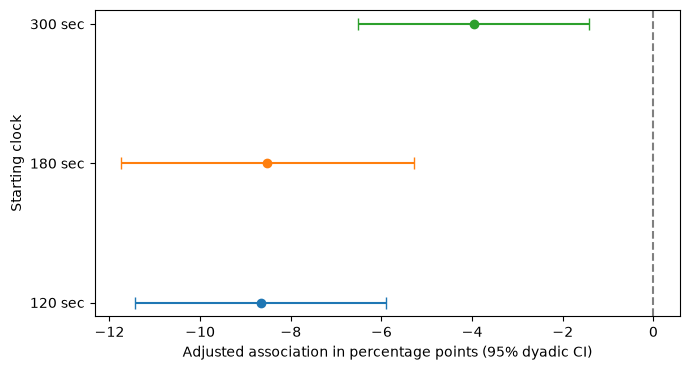

In [6]:
fig,ax=plt.subplots(figsize=(7,3.8))
for i,r in enumerate(dyadic.itertuples()):
    ax.errorbar(r.estimate*100,i,xerr=[[100*(r.estimate-r.lower)],[100*(r.upper-r.estimate)]],fmt='o',capsize=4)
ax.set_yticks(range(len(dyadic)),[f'{int(x)} sec' for x in dyadic.clock]);ax.axvline(0,color='gray',ls='--')
ax.set_xlabel('Adjusted association in percentage points (95% dyadic CI)')
ax.set_ylabel('Starting clock')
plt.tight_layout();plt.show()

## 6. Sensitivity to an omitted binary confounder (illustrative bias scenarios)

A simple **bias-budget** thought experiment: if an omitted binary characteristic is more prevalent in treated versus control games by `Δ prevalence`, and raises timeout-loss probability by `Δ risk` (on an additive scale), the approximate bias is their product. This relationship is an **illustrative sensitivity parameterization**, not a formally identified correction and not empirical evidence that such a confounder exists. It omits interactions and adjustment-induced complications.

Display the combinations of prevalence imbalance and conditional risk shift that would be **large enough in magnitude** to explain each stratum's adjusted estimate. This is not a robustness bound or a proof of causal impact.

In [7]:
# Use the game-level dyadic adjusted estimates solely for an illustrative arithmetic exercise.
rows=[]
for r in dyadic.itertuples():
    for imbalance in [0.10,0.20,0.30,0.40]:
        rows.append({'clock':r.clock,'absolute_prevalence_imbalance':imbalance,
                     'risk_difference_needed_to_offset':abs(r.estimate)/imbalance})
tipping=pd.DataFrame(rows)
display(tipping.assign(**{'required_risk_shift_pct':lambda x:(x.risk_difference_needed_to_offset*100).round(1)})
        [['clock','absolute_prevalence_imbalance','required_risk_shift_pct']])
print('Interpret required shifts >100% as impossible under this simplified binary-risk model, not evidence of identification.')

,clock,absolute_prevalence_imbalance,required_risk_shift_pct
0,120,0.1,86.6
1,120,0.2,43.3
2,120,0.3,28.9
3,120,0.4,21.7
4,180,0.1,85.1
5,180,0.2,42.6
6,180,0.3,28.4
7,180,0.4,21.3
8,300,0.1,39.7
9,300,0.2,19.8


Interpret required shifts >100% as impossible under this simplified binary-risk model, not evidence of identification.


## 7. Diagnostics summary and export

AIPW and IPW differ from the main Notebook 4 regression because of nuisance-model choice and weighting. The dyadic result differs *also* in unit of analysis and covariate structure. All of these remain observational results.

In [8]:
out = ROOT/'results'/'tables'; out.mkdir(parents=True,exist_ok=True)
for name,table in [('05_aipw_ipw.csv',robust),('05_weighted_balance.csv',balance),
                   ('05_dyadic_game_regression.csv',dyadic),('05_unobserved_bias_scenarios.csv',tipping)]:
    table.to_csv(out/name,index=False)
print('Saved four tables to',out)

Saved four tables to c:\Users\jenny\Projects\lichess-increment-causal-inference\results\tables


## 8. Interpretation and Design Decision Log

### A. Agreement Across Models

The negative association between a 2-second increment and timeout-loss probability persisted across all four estimation approaches.

| Starting clock | Raw difference | IPW | Cross-fitted AIPW | Game-level dyadic regression |
|---|---:|---:|---:|---:|
| 120 seconds | −8.84 pp | −8.46 pp | −8.28 pp | −8.66 pp |
| 180 seconds | −8.31 pp | −8.47 pp | −8.32 pp | −8.51 pp |
| 300 seconds | −3.86 pp | −4.07 pp | −4.04 pp | −3.97 pp |

The results were remarkably consistent across specifications. For the 120-second stratum, estimates ranged from −8.28 to −8.84 percentage points. For the 180-second stratum, estimates ranged from −8.31 to −8.51 percentage points. For the 300-second stratum, estimates ranged from −3.86 to −4.07 percentage points.

The cross-fitted AIPW estimates were −8.28, −8.32, and −4.04 percentage points, respectively.

The similarity between IPW and AIPW estimates suggests that the observed negative association is not highly sensitive to these particular modeling choices.

However, these estimators are not directly interchangeable. The raw, IPW, and AIPW estimates use player-game observations. The dyadic regression uses one observation per game, with the outcome defined as the fraction of players losing on time.

Although both approaches use the probability scale, the dyadic regression adjusts for mean game Elo rather than focal-player Elo. Consequently, it estimates a differently adjusted association.

**Decision:** Retain the regression-adjusted results from Notebook 4 as the primary analysis, use AIPW and IPW as robustness checks, and present dyadic regression as an additional sensitivity analysis with improved treatment of player-network dependence.

### B. Propensity Weight Stability and Covariate Balance

The propensity-score diagnostics showed generally adequate overlap in the measured covariates.

| Starting clock | Propensity range | Clipped observations | Maximum weight |
|---|---|---:|---:|
| 120 seconds | 0.118–0.228 | 0.00% | 8.51 |
| 180 seconds | 0.046–0.232 | 0.33% | 20.00 |
| 300 seconds | 0.157–0.311 | 0.00% | 6.11 |

Most estimated treatment probabilities remained within the prespecified clipping bounds of 0.05–0.95.

Only the 180-second stratum required noticeable clipping, affecting approximately 0.33% of observations. Its maximum inverse-propensity weight reached 20, making it the most potentially sensitive stratum to weighting instability.

The effective sample sizes (ESS) were:

| Starting clock | Treated ESS | Control ESS |
|---|---:|---:|
| 120 seconds | 2,400 | 11,895 |
| 180 seconds | 2,103 | 16,449 |
| 300 seconds | 5,925 | 20,327 |

These values indicate that the weights did not cause a severe collapse in effective sample size. Nevertheless, the treated groups were substantially smaller than their corresponding control groups.

Inverse-propensity weighting also improved the balance of measured covariates.

| Starting clock | Covariate | Raw SMD | Weighted SMD |
|---|---|---:|---:|
| 120 sec | Player Elo | 0.072 | 0.001 |
| 120 sec | UTC hour sine | −0.041 | −0.007 |
| 120 sec | UTC hour cosine | 0.079 | −0.006 |
| 180 sec | Player Elo | −0.093 | 0.019 |
| 180 sec | UTC hour sine | −0.373 | −0.010 |
| 180 sec | UTC hour cosine | −0.064 | −0.046 |
| 300 sec | Player Elo | −0.094 | −0.010 |
| 300 sec | UTC hour sine | −0.027 | 0.013 |
| 300 sec | UTC hour cosine | −0.074 | 0.002 |

All weighted absolute SMDs were below 0.05.

The most substantial improvement occurred for the 180-second stratum's UTC-hour sine variable, where the SMD decreased from −0.373 to −0.010.

This indicates that IPW achieved good balance across the measured rating and time-of-day variables included in the propensity model.

However, it does not establish balance in unmeasured characteristics or guarantee that the propensity model is correctly specified.

**Decision:** Retain IPW and cross-fitted AIPW as credible sensitivity analyses for observed-covariate adjustment, while recognizing that neither method eliminates unmeasured confounding.

### C. Player-Network-Aware Statistical Uncertainty

The game-level dyadic regression accounted for dependence between games sharing either participant.

The adjusted estimates and approximate 95% confidence intervals were:

| Starting clock | Adjusted difference | Dyadic 95% CI |
|---|---:|---:|
| 120 seconds | −8.66 pp | [−11.43, −5.90] |
| 180 seconds | −8.51 pp | [−11.74, −5.29] |
| 300 seconds | −3.97 pp | [−6.51, −1.42] |

All three confidence intervals excluded zero under the dyadic variance approximation.

This provides evidence that the negative associations persist when accounting for some of the dependence created by players appearing across multiple games.

Unlike conventional clustering by focal-player identifier, this approximation incorporates games sharing either participant, including instances where a player appears as White in one game and Black in another.

However, several limitations remain.

First, the dyadic estimator relies on the sandwich-variance approximation and its assumptions about dependence among games.

Second, the analysis uses a game-level outcome and adjusts for mean game Elo, whereas Notebook 4 used a player-level outcome and adjusted for focal-player Elo.

Third, dependence may extend beyond shared-player identities through temporal patterns, common matchmaking conditions, or other unobserved influences.

Thus, the dyadic results strengthen the uncertainty analysis but do not definitively resolve all dependence concerns.

**Decision:** Report dyadic confidence intervals as network-aware sensitivity estimates. Avoid treating them as interchangeable with Notebook 4's player-level confidence intervals or as proof of causal identification.

### D. Sensitivity to Unobserved Selection

The omitted-variable sensitivity analysis considered hypothetical binary confounders that differed in prevalence between treatment groups and influenced timeout-loss risk.

For example, in the 300-second stratum, the game-level adjusted association was approximately −3.97 percentage points.

Under the simplified additive-bias model, an unobserved characteristic with a 20-percentage-point prevalence imbalance between treated and untreated games would need to change timeout-loss probability by approximately 19.8 percentage points to generate bias of this magnitude.

For comparison:

| Starting clock | Hypothetical prevalence imbalance | Required risk difference |
|---|---:|---:|
| 120 seconds | 20 pp | 43.3 pp |
| 180 seconds | 20 pp | 42.6 pp |
| 300 seconds | 20 pp | 19.8 pp |

These scenarios illustrate the combinations of confounder imbalance and outcome association that could offset the observed estimates.

The 300-second result appears more vulnerable to a hypothetical confounder with a moderate association with timeout risk because the observed adjusted difference is smaller.

The larger negative associations at 120 and 180 seconds require correspondingly larger bias products under this simplified model.

However, the analysis does not measure such a confounder or establish whether the hypothetical scenarios are realistic.

The calculations also assume an additive relationship and omit interactions and complications from the existing adjustment strategy. They should therefore be interpreted as illustrative bias scenarios rather than formal corrections or proof that the observed associations are robust to all plausible unmeasured confounding.

**Decision:** Present the sensitivity table to demonstrate how unmeasured confounding might affect interpretation, without claiming that it rules out alternative explanations.

### E. Final Interpretation and Causal Identification

Across all examined methods, selecting a time-control queue with a 2-second increment was consistently associated with a lower probability of losing on time.

The adjusted associations were approximately 8–9 percentage points lower for 120- and 180-second starting clocks and approximately 4 percentage points lower for 300-second starting clocks.

The negative direction persisted across ordinary regression adjustment, IPW, cross-fitted AIPW, within-player fixed effects in Notebook 4, and the game-level dyadic regression.

This consistency suggests that the association is not an artifact of one particular statistical estimator or a small subset of highly influential observations.

However, **consistency across observational models does not establish a causal effect**.

Interpreting the estimates as the causal effect of choosing an increment queue would require several assumptions:

1. **Conditional exchangeability:** After accounting for relevant pre-treatment characteristics, players choosing increment and non-increment queues would have comparable potential outcomes.
2. **Positivity:** Players in the target population must have a nonzero probability of choosing either queue.
3. **Consistency and treatment definition:** The intervention must clearly represent choosing a particular time-control policy before matchmaking.
4. **Appropriate handling of dependence:** Statistical inference must recognize repeated players and shared games.
5. **Sufficient measurement and model validity:** The observed covariates and modeling strategy must adequately represent the relevant confounding structure.

The most significant remaining threat is unmeasured selection into time controls.

Players who prefer increments may differ in time-management ability, risk tolerance, motivation, or playing style. These characteristics could influence timeout losses independently of the increment policy.

Moreover, selecting a different time-control queue may change the opponent encountered. Therefore, the total queue-choice effect cannot automatically be interpreted as the isolated effect of adding two seconds to an otherwise identical game.

A randomized experiment assigning comparable players to different clock policies would provide stronger evidence for a clock-only causal effect. A credible natural experiment that shifts time-control selection independently of underlying player characteristics could also strengthen identification of a queue-choice effect.

### Final Conclusion

The results provide consistent observational evidence that games played with a 2-second increment are associated with lower timeout-loss probabilities across all three starting-clock durations.

The association remained negative after adjusting for measured covariates, applying propensity-based methods, examining within-player comparisons, and incorporating player-network-aware uncertainty.

Nevertheless, unobserved selection into time controls and uncertainty about the appropriate causal intervention prevent a definitive causal interpretation.

**The appropriate conclusion is that a 2-second increment is consistently associated with fewer timeout losses in this dataset, but the magnitude of its causal effect has not been identified.**

These findings are based on one month of Lichess data from January 2013. Generalization to contemporary players, time-control preferences, and matchmaking conditions remains uncertain.